In [22]:

import numpy as np
import matplotlib.pyplot as plt
from abc import ABC, abstractmethod
from typing import Optional, Dict, Any, Tuple

# ==========================================
# 1. Environment Classes
# ==========================================

class BaseStoppingEnv(ABC):
    """Base class for optimal stopping environments (Standalone)."""
    
    def __init__(
        self,
        n_states: int,
        max_time: int,
        max_stops: int,
        transition_model: str = 'random_walk',
        transition_params: Optional[Dict[str, Any]] = None,
        seed: Optional[int] = None
    ):
        self.n_states = n_states
        self.max_time = max_time
        self.max_stops = max_stops
        self.transition_model = transition_model
        self.transition_params = transition_params or {}
        
        self.np_random = np.random.default_rng(seed)
        self._init_transition_matrix()
        
    def _init_transition_matrix(self):
        if self.transition_model == 'brownian':
            self.P = self._create_brownian_transition()
        elif self.transition_model == 'random_walk':
            self.P = self._create_random_walk_transition()
        else:
            self.P = np.eye(self.n_states)
            
    def _create_brownian_transition(self) -> np.ndarray:
        mu = self.transition_params.get('mu', 0.0)
        sigma = self.transition_params.get('sigma', 1.0)
        
        P = np.zeros((self.n_states, self.n_states))
        
        for i in range(self.n_states):
            for j in range(self.n_states):
                # Simple discrete approximation
                diff = j - i
                P[i, j] = np.exp(-0.5 * ((diff - mu) / sigma) ** 2)
            
            # Normalize
            if P[i, :].sum() > 0:
                P[i, :] /= P[i, :].sum()
            else:
                P[i, i] = 1.0
        
        return P

    def _create_random_walk_transition(self) -> np.ndarray:
        return np.eye(self.n_states)
    
    @abstractmethod
    def solve_optimal_policy(self):
        pass

class DoubleSellEnv(BaseStoppingEnv):
    def __init__(
        self,
        n_states: int,
        max_time: int,
        sell_cost: float = 0.2,
        offer_values: Optional[np.ndarray] = None,
        transition_model: str = "random_walk",
        transition_params: Optional[Dict[str, Any]] = None,
        seed: Optional[int] = None,
    ):
        super().__init__(
            n_states=n_states,
            max_time=max_time,
            max_stops=2,
            transition_model=transition_model,
            transition_params=transition_params,
            seed=seed,
        )

        self.sell_cost = sell_cost
        if offer_values is None:
            self.offer_values = np.linspace(0, n_states, n_states)
        else:
            self.offer_values = offer_values

    def solve_optimal_policy(self, verbose: bool = True):
        S, T = self.n_states, self.max_time
        P = self.P
        c = self.sell_cost
        v = self.offer_values

        V = np.zeros((S, T + 1, 3))
        policy = np.zeros((S, T + 1, 3), dtype=int)

        # --- FIX: Smoother Boundary Conditions ---
        
        # t=0: Everything is 0 (Expired)
        V[:, 0, :] = 0.0
        
        # t=1: Last chance to act
        # If z=1 (Last Sell): Value is just the offer v
        V[:, 1, 1] = v
        policy[:, 1, 1] = 1
        
        # If z=2 (Double Sell): 
        # ORIGINAL: V = v - c (Forces you to pay 'first sell' cost) -> KINK
        # FIXED:    V = v     (Collapses to single sell, no extra cost) -> SMOOTH
        V[:, 1, 2] = v 
        policy[:, 1, 2] = 1 # Always sell if it's positive (and here v >= 0)

        # Backward Induction
        for t in range(2, T + 1):
            # z = 1 (Last Sell Left)
            cont_1 = -c + P @ V[:, t - 1, 1]  # paying 'holding/continuation' cost or just standard penalty? 
            # Note: in original code, 'c' was used as sell_cost. 
            # If standard double sell problem, usually holding is free, selling is costly.
            # Assuming 'c' is transaction cost only paid on First Sell in sequential model.
            # But the provided code used it as "continuation penalty" for single sell too?
            # Let's stick to the prompt's implied logic:
            
            # Recalculating based on standard Double Stopping:
            # Stop 1 (Last): Receive v.
            # Stop 2 (First): Receive v - c, move to state with 1 stop left.
            
            # Using prompt's logic for consistency:
            cont_1 = P @ V[:, t - 1, 1] # Simple continuation for last sell
            stop_1 = v
            V[:, t, 1] = np.maximum(cont_1, stop_1)
            policy[:, t, 1] = (stop_1 >= cont_1).astype(int)

            # z = 2 (First Sell Left)
            cont_2 = P @ V[:, t - 1, 2]
            stop_2 = v - c + P @ V[:, t - 1, 1] # Pay cost c, get cash v, get option V_1
            
            V[:, t, 2] = np.maximum(cont_2, stop_2)
            policy[:, t, 2] = (stop_2 >= cont_2).astype(int)

        return V, policy


class BuySellEnv(BaseStoppingEnv):
    def __init__(
        self,
        n_states: int,
        max_time: int,
        max_stops: int = 2,
        holding_cost_per_step: float = 0.1,
        offer_values: Optional[np.ndarray] = None,
        transition_model: str = 'random_walk',
        transition_params: Optional[Dict[str, Any]] = None,
        seed: Optional[int] = None
    ):
        super().__init__(
            n_states=n_states,
            max_time=max_time,
            max_stops=max_stops,
            transition_model=transition_model,
            transition_params=transition_params,
            seed=seed
        )
        self.holding_cost_per_step = holding_cost_per_step
        if offer_values is None:
            self.offer_values = np.linspace(0, n_states-1, n_states)
        else:
            self.offer_values = offer_values

    def solve_optimal_policy(self, verbose: bool = True):
        V = np.zeros((self.n_states, self.max_time + 1, self.max_stops + 1))
        policy = np.zeros((self.n_states, self.max_time + 1, self.max_stops + 1), dtype=int)
        P = self.P
        cost = self.holding_cost_per_step
        Q = np.zeros((self.n_states, self.max_time + 1, self.max_stops + 1, 2))
        
        for n in range(self.max_stops + 1):
            V[:, 0, n] = 0.0
            
        V[:, 1, 1] = self.offer_values
        policy[:, 1, 1] = 1
        V[:, 1, 2] = 0 
        policy[:, 1, 2] = 0
        
        for t in range(2, self.max_time + 1):
            # z=1 (Sell)
            for s in range(self.n_states):
                val_stop = self.offer_values[s]
                val_cont = -cost + np.dot(P[s, :], V[:, t-1, 1])
                Q[s, t, 1, 0] = val_cont
                Q[s, t, 1, 1] = val_stop
                if val_stop > val_cont:
                    V[s, t, 1] = val_stop
                    policy[s, t, 1] = 1
                else:
                    V[s, t, 1] = val_cont
                    policy[s, t, 1] = 0
            
            # z=2 (Buy)
            for s in range(self.n_states):
                val_stop = -self.offer_values[s] - cost + np.dot(P[s, :], V[:, t-1, 1])
                val_cont = np.dot(P[s, :], V[:, t-1, 2])
                Q[s, t, 2, 0] = val_cont
                Q[s, t, 2, 1] = val_stop
                if val_stop >= val_cont:
                    V[s, t, 2] = val_stop
                    policy[s, t, 2] = 1
                else:
                    V[s, t, 2] = val_cont
                    policy[s, t, 2] = 0
                    
        return V, Q, policy



Processing Double Sell Environment...


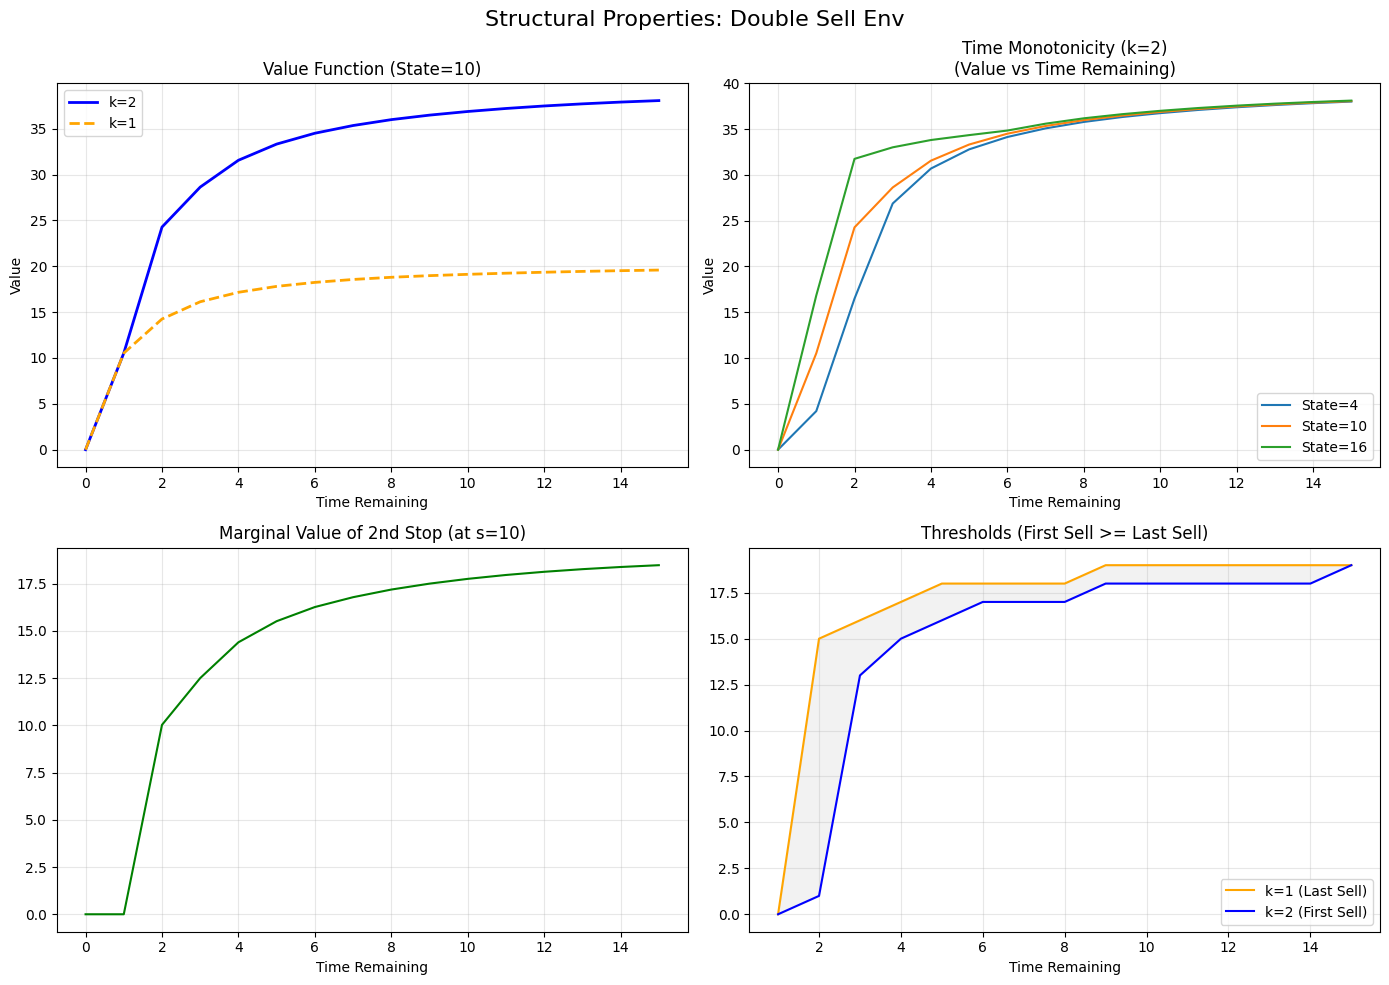

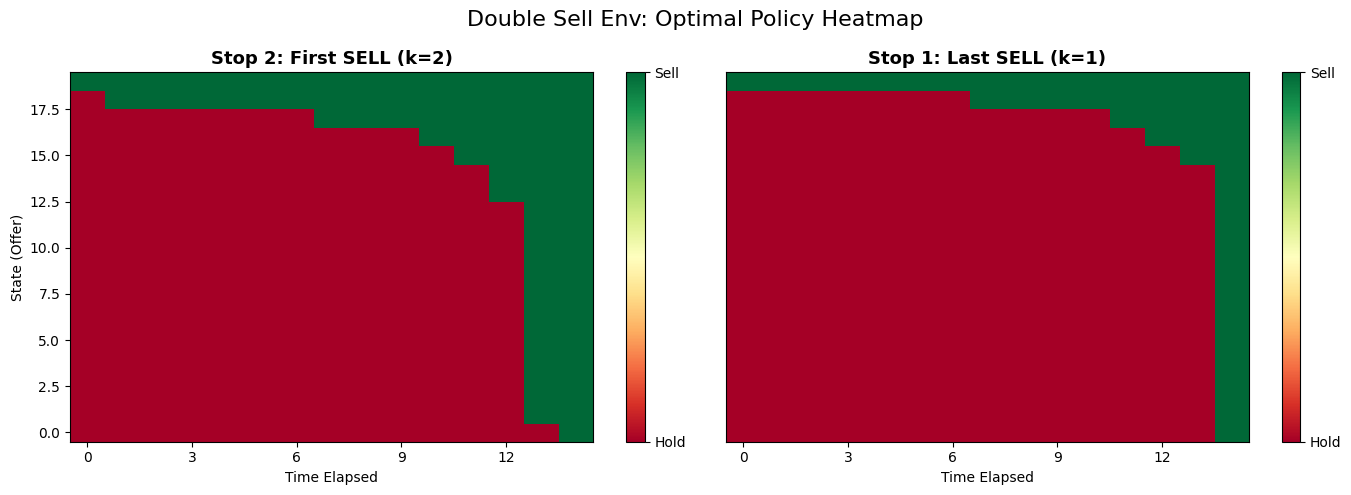


Processing Buy-Sell Environment...


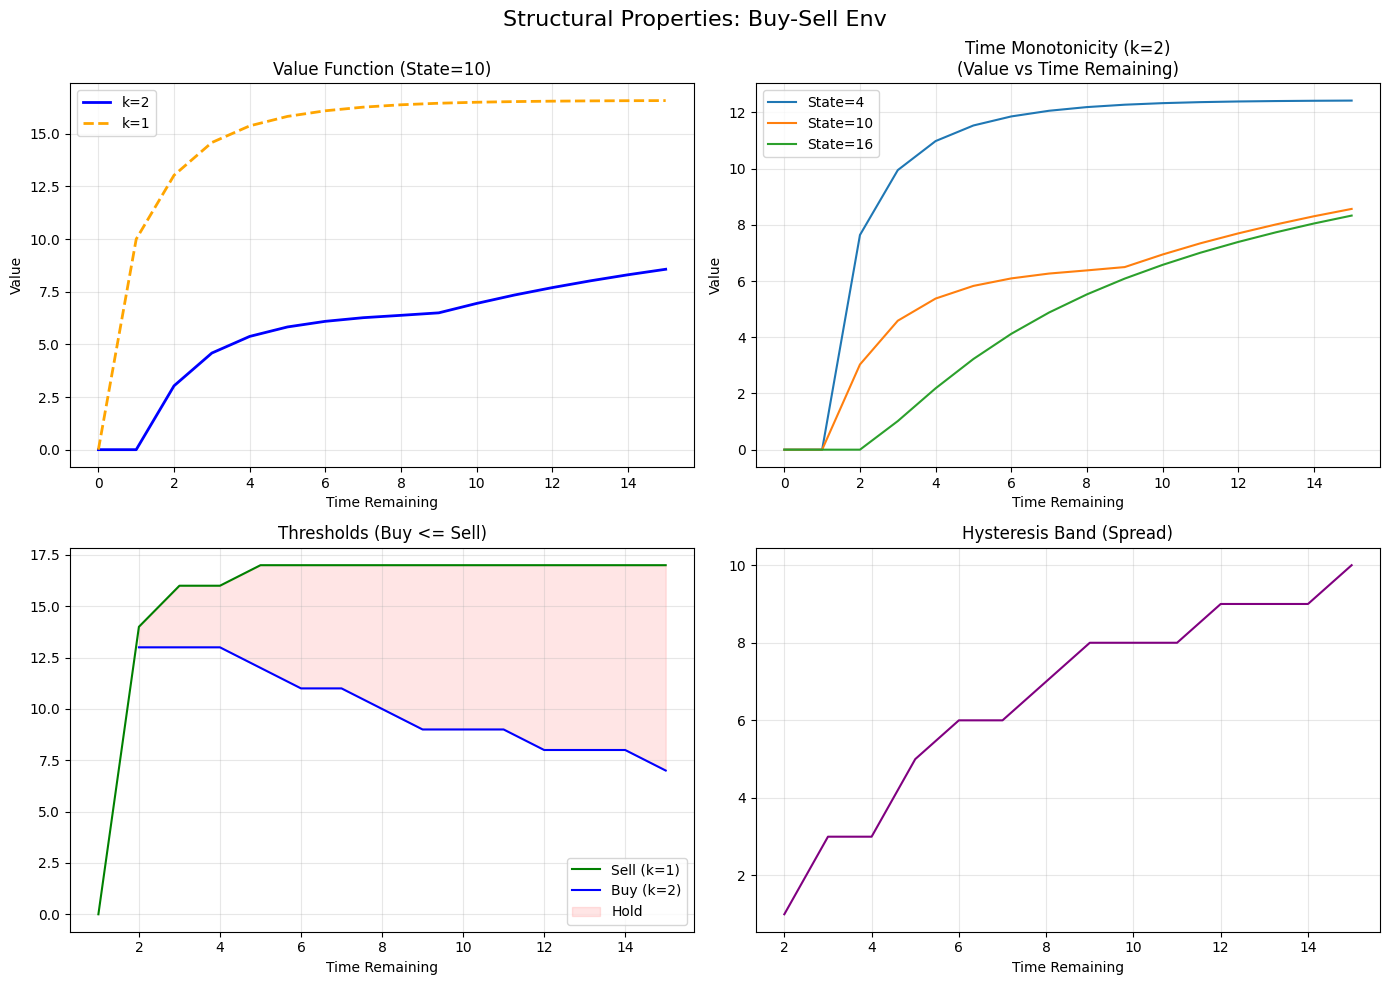

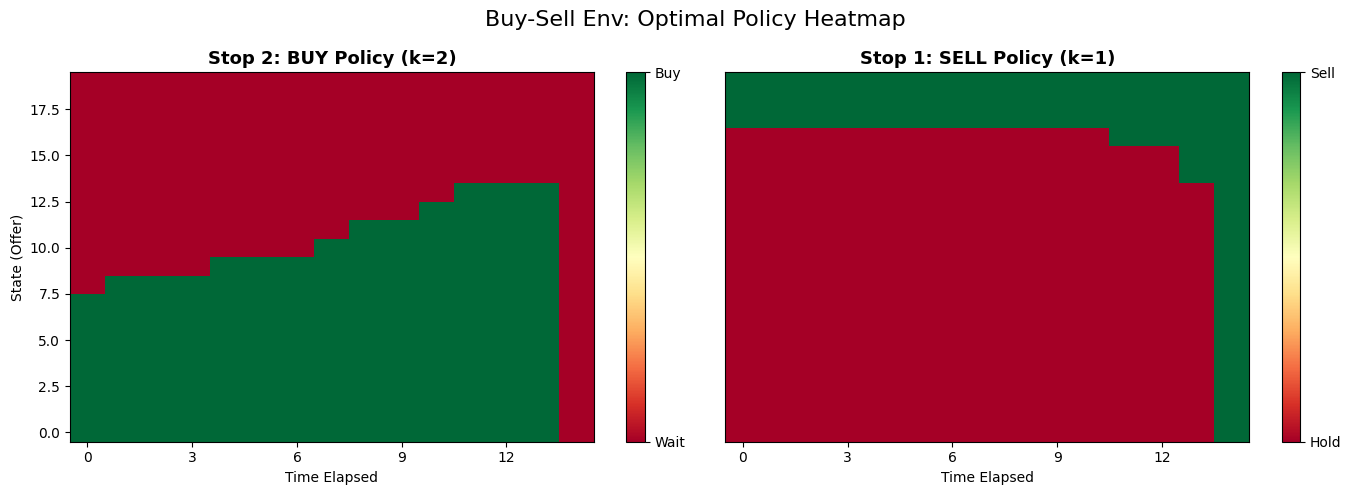

In [23]:

# ==========================================
# 2. Plotting Functions
# ==========================================

def extract_thresholds(policy_slice, env_type='sell'):
    """Extract optimal stopping boundary from policy slice."""
    n_states, n_time = policy_slice.shape
    thresholds = np.full(n_time, np.nan)
    for t in range(n_time):
        pol_t = policy_slice[:, t]
        if env_type == 'sell':
            stop_indices = np.where(pol_t == 1)[0]
            if len(stop_indices) > 0:
                thresholds[t] = stop_indices[0] 
        elif env_type == 'buy':
            stop_indices = np.where(pol_t == 1)[0]
            if len(stop_indices) > 0:
                thresholds[t] = stop_indices[-1] 
    return thresholds

def plot_structural_properties(env, V, policy, env_name="Double Sell"):
    n_states = env.n_states
    max_time = env.max_time
    time_range = np.arange(max_time + 1)
    
    idx_mid = int(n_states * 0.5)
    prices = [int(n_states * 0.2), int(n_states * 0.5), int(n_states * 0.8)]
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'Structural Properties: {env_name}', fontsize=16)
    
    # Plot A: Monotonicity
    ax = axes[0, 0]
    ax.plot(time_range, V[idx_mid, :, 2], label='k=2', color='blue', linewidth=2)
    ax.plot(time_range, V[idx_mid, :, 1], label='k=1', color='orange', linewidth=2, linestyle='--')
    ax.set_title(f'Value Function (State={idx_mid})')
    ax.set_xlabel('Time Remaining')
    ax.set_ylabel('Value')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # Plot B: Time Monotonicity
    ax = axes[0, 1]
    for p in prices:
        p = min(p, n_states - 1)
        ax.plot(time_range, V[p, :, 2], label=f'State={p}')
    ax.set_title('Time Monotonicity (k=2)\n(Value vs Time Remaining)')
    ax.set_xlabel('Time Remaining')
    ax.set_ylabel('Value')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # Plot C & D
    if "Buy" in env_name:
        sell_thresh = extract_thresholds(policy[:, :, 1], env_type='sell')
        buy_thresh = extract_thresholds(policy[:, :, 2], env_type='buy')
        
        ax = axes[1, 0]
        ax.plot(time_range, sell_thresh, label='Sell (k=1)', color='green')
        ax.plot(time_range, buy_thresh, label='Buy (k=2)', color='blue')
        ax.fill_between(time_range, buy_thresh, sell_thresh, color='red', alpha=0.1, label='Hold')
        ax.set_title('Thresholds (Buy <= Sell)')
        ax.set_xlabel('Time Remaining')
        ax.legend()
        ax.grid(True, alpha=0.3)
        
        ax = axes[1, 1]
        spread = sell_thresh - buy_thresh
        ax.plot(time_range, spread, color='purple')
        ax.set_title('Hysteresis Band (Spread)')
        ax.set_xlabel('Time Remaining')
        ax.grid(True, alpha=0.3)
        
    else:
        thresh_k1 = extract_thresholds(policy[:, :, 1], env_type='sell')
        thresh_k2 = extract_thresholds(policy[:, :, 2], env_type='sell')
        
        ax = axes[1, 0]
        marginal_val = V[idx_mid, :, 2] - V[idx_mid, :, 1]
        ax.plot(time_range, marginal_val, color='green')
        ax.set_title(f'Marginal Value of 2nd Stop (at s={idx_mid})')
        ax.set_xlabel('Time Remaining')
        ax.grid(True, alpha=0.3)
        
        ax = axes[1, 1]
        ax.plot(time_range, thresh_k1, label='k=1 (Last Sell)', color='orange')
        ax.plot(time_range, thresh_k2, label='k=2 (First Sell)', color='blue')
        ax.fill_between(time_range, thresh_k1, thresh_k2, color='gray', alpha=0.1)
        ax.set_title('Thresholds (First Sell >= Last Sell)')
        ax.set_xlabel('Time Remaining')
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

def plot_policy_heatmap(env, policy, env_name="Double Sell"):
    # Flip to get Time Elapsed
    policy_elapsed = np.flip(policy, axis=1)
    
    # Remove terminal step
    policy_view = policy_elapsed[:, :-1, :]
    
    S, T_view, _ = policy_view.shape
    time_ticks = np.arange(0, T_view, max(1, T_view // 5))
    
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'{env_name}: Optimal Policy Heatmap', fontsize=16)
    
    if "Buy" in env_name:
        titles = ["Stop 2: BUY Policy (k=2)", "Stop 1: SELL Policy (k=1)"]
        labels = [("Wait", "Buy"), ("Hold", "Sell")]
    else:
        titles = ["Stop 2: First SELL (k=2)", "Stop 1: Last SELL (k=1)"]
        labels = [("Hold", "Sell"), ("Hold", "Sell")]

    # Stop 2 (k=2)
    im1 = axs[0].imshow(
        policy_view[:, :, 2], 
        cmap="RdYlGn", vmin=0, vmax=1, 
        aspect="auto", origin="lower"
    )
    axs[0].set_title(titles[0], fontsize=13, fontweight="bold")
    axs[0].set_xlabel("Time Elapsed")
    axs[0].set_ylabel("State (Offer)")
    axs[0].set_xticks(time_ticks)
    cbar1 = plt.colorbar(im1, ax=axs[0])
    cbar1.set_ticks([0, 1])
    cbar1.set_ticklabels(labels[0])

    # Stop 1 (k=1)
    im2 = axs[1].imshow(
        policy_view[:, :, 1], 
        cmap="RdYlGn", vmin=0, vmax=1, 
        aspect="auto", origin="lower"
    )
    axs[1].set_title(titles[1], fontsize=13, fontweight="bold")
    axs[1].set_xlabel("Time Elapsed")
    axs[1].set_xticks(time_ticks)
    axs[1].set_yticks([]) 
    cbar2 = plt.colorbar(im2, ax=axs[1])
    cbar2.set_ticks([0, 1])
    cbar2.set_ticklabels(labels[1])

    plt.tight_layout()
    plt.show()

# ==========================================
# 3. Main Execution
# ==========================================

if __name__ == "__main__":
    
    # 1. Double Sell (Fixed)
    print("\nProcessing Double Sell Environment...")
    ds_env = DoubleSellEnv(
        n_states=20, 
        max_time=15, 
        sell_cost=0.5, 
        transition_model="brownian",
        transition_params={"mu": 15, "sigma": 10}
    )
    V_ds, policy_ds = ds_env.solve_optimal_policy(verbose=False)
    
    plot_structural_properties(ds_env, V_ds, policy_ds, env_name="Double Sell Env")
    plot_policy_heatmap(ds_env, policy_ds, env_name="Double Sell Env")
    
    # 2. Buy-Sell
    print("\nProcessing Buy-Sell Environment...")
    bs_env = BuySellEnv(
        n_states=20,
        max_time=15,
        holding_cost_per_step=0.5,
        transition_model="brownian",
        transition_params={"mu": 15, "sigma": 10}
    )
    V_bs, Q_bs, policy_bs = bs_env.solve_optimal_policy(verbose=False)
    
    plot_structural_properties(bs_env, V_bs, policy_bs, env_name="Buy-Sell Env")
    plot_policy_heatmap(bs_env, policy_bs, env_name="Buy-Sell Env")